# Mejorar el modelo con fotos propias (fine-tuning con datos reales)
### Proyecto final — Inteligencia Artificial (Deep Learning) — Notebook 03
---
**El problema:** ResNet18 sacó **99.85%** en el test de Kaggle, pero con la webcam **predecía mal**. ¿Cómo puede ser?

1. **Domain shift (cambio de dominio):** las fotos de Kaggle son de "estudio": una fruta sobre **fondo blanco** y con buena luz. La webcam muestra **otro mundo**: tu cuarto, tu mano, tu cara y luz de foco. Además, las naranjas de aquí son **verde-amarillas** y las del dataset son naranja intenso. El modelo nunca vio nada parecido.
2. **Data leakage:** el test de Kaggle tiene copias rotadas de fotos de train (ver el notebook 01). El 99.85% medía "reconocer variantes de fotos conocidas", no "funcionar en el mundo real".
3. **No existe la opción "no hay fruta":** con softmax, el modelo **siempre** elige una de las 6 clases, aunque le muestres una pared.

**La solución (lo que se hace en la industria):**
- Juntar **datos del dominio real**: fotos tomadas con **nuestra** cámara, en **nuestro** ambiente (con `src/capturar.py`).
- Agregar una clase **`nada`** (sin fruta).
- Usar **augmentation más fuerte**: recortes y zoom aleatorios y más variación de luz.
- **Reentrenar** (fine-tuning) con Kaggle + fotos propias.
- Evaluar **honestamente** en fotos propias que el modelo **no vio** al entrenar, comparando **antes y después**.

## 1. Librerías, rutas y semillas

In [1]:
import sys, time, copy, json, random  # Utilidades estándar
from pathlib import Path  # Rutas
from collections import Counter  # Para contar fotos por clase

import numpy as np  # Arrays
import matplotlib.pyplot as plt  # Gráficos
import seaborn as sns  # Matriz de confusión
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report  # Métricas
from PIL import Image  # Abrir imágenes

import torch  # PyTorch
import torch.nn as nn  # Capas y pérdidas
import torchvision.transforms as transforms  # Preprocesamiento
from torch.utils.data import DataLoader  # Carga por batches
from torchvision.models import resnet18, ResNet18_Weights  # ResNet18 preentrenada

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")  # GPU si hay
print("Dispositivo:", device)
SEMILLA = 42
random.seed(SEMILLA); np.random.seed(SEMILLA); torch.manual_seed(SEMILLA)  # Reproducibilidad

RAIZ = Path("..")  # Raíz del proyecto
DATA_DIR, MODELS_DIR, OUTPUTS_DIR = RAIZ / "data", RAIZ / "models", RAIZ / "outputs"
PROPIAS_DIR = DATA_DIR / "propias"  # Fotos tomadas con src/capturar.py
sys.path.append(str(RAIZ.resolve()))  # Para importar src/

Dispositivo: cuda


## 2. Hiperparámetros

- **`REPETIR_PROPIAS`:** tenemos ~9,000 fotos de Kaggle y solo unos cientos propias. Si las mezclamos tal cual, las propias serían ~3% de lo que ve la red y casi no influirían. Por eso **repetimos** las fotos propias varias veces en cada epoch (*oversampling*). Como el augmentation es aleatorio, cada repetición sale un poco distinta.
- **`FRACCION_TEST_PROPIAS`:** separamos el 30% de las fotos propias para evaluar, y la red **nunca** las ve al entrenar.

In [2]:
IMG_SIZE = 224             # ResNet18 trabaja con 224x224
BATCH_SIZE = 64            # Imágenes por batch
EPOCHS_CABEZA = 2          # Etapa 1: solo la capa final
EPOCHS_FINE = 5            # Etapa 2: fine-tuning de layer3 + layer4 + fc
LR_CABEZA, LR_FINE = 1e-3, 1e-4  # Learning rates de cada etapa
REPETIR_PROPIAS = 8        # Cuántas veces se repiten las fotos propias en cada epoch (oversampling)
FRACCION_TEST_PROPIAS = 0.3  # 30% de las fotos propias se reserva para evaluar
NUM_WORKERS = 4            # Si Jupyter se cuelga en Windows, poner 0
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]  # Normalización de ImageNet

## 3. Fotos propias: conteo y split *por tiempo*

**Ojo con cómo se separan:** las fotos de una ráfaga, tomadas con 0.3 s de diferencia, son **casi idénticas**. Si las repartiéramos al azar entre train y test, el test tendría "gemelas" de fotos de train y volveríamos a tener *data leakage*, el mismo problema del dataset de Kaggle.

Por eso separamos **por tiempo**: dentro de cada clase ordenamos las fotos por la hora en que se tomaron (el nombre del archivo es la fecha y hora) y usamos el **último 30%** como test. Así el test son "otros momentos" de la captura, con otra posición y otra luz.

In [3]:
EXT = {".jpg", ".jpeg", ".png", ".webp"}
fotos_propias = {c.name: sorted(p for p in c.iterdir() if p.suffix.lower() in EXT)  # Ordenadas por nombre = por hora
                 for c in sorted(PROPIAS_DIR.iterdir()) if c.is_dir()}
fotos_propias = {c: f for c, f in fotos_propias.items() if f}  # Ignora carpetas vacías

kaggle_clases = sorted(p.name for p in (DATA_DIR / "train").iterdir() if p.is_dir())  # Las 6 de Kaggle
clases = sorted(set(kaggle_clases) | set(fotos_propias))  # Unión: las 6 + "nada" si capturaste fotos sin fruta
idx = {c: i for i, c in enumerate(clases)}  # Clase -> índice de salida de la red
NOMBRES_ES = {"freshapples": "Manzana fresca", "freshbanana": "Banana fresca", "freshoranges": "Naranja fresca",
              "rottenapples": "Manzana podrida", "rottenbanana": "Banana podrida", "rottenoranges": "Naranja podrida",
              "nada": "Sin fruta"}
nombres = [NOMBRES_ES[c] for c in clases]
print("Clases del nuevo modelo:", clases)

propias_train, propias_test = [], []  # Listas de (ruta, índice de clase)
print(f"\n{'clase':<16}{'fotos':>6}{'train':>7}{'test':>6}")
for c, fotos in fotos_propias.items():
    n_test = int(round(len(fotos) * FRACCION_TEST_PROPIAS)) if len(fotos) >= 4 else 0  # Con <4 fotos, todas a train
    corte = len(fotos) - n_test
    propias_train += [(p, idx[c]) for p in fotos[:corte]]  # Las primeras (más antiguas) a train
    propias_test += [(p, idx[c]) for p in fotos[corte:]]  # Las últimas (más nuevas) a test
    print(f"{c:<16}{len(fotos):>6}{corte:>7}{n_test:>6}")
print(f"\nTotal propias: train={len(propias_train)}  test={len(propias_test)}")

Clases del nuevo modelo: ['freshapples', 'freshbanana', 'freshoranges', 'nada', 'rottenapples', 'rottenbanana', 'rottenoranges']

clase            fotos  train  test
freshapples         11      8     3
freshbanana          7      5     2
freshoranges         7      5     2
nada                 3      3     0
rottenoranges        7      5     2

Total propias: train=26  test=9


## 4. Un `Dataset` propio

Hasta ahora usamos `ImageFolder`, que lee una carpeta. Ahora mezclamos **dos fuentes** (Kaggle y fotos propias) con clases distintas (las propias pueden incluir `nada`). Lo más claro es escribir **nuestro propio Dataset**: una clase con dos métodos.
- `__len__`: cuántas imágenes hay.
- `__getitem__(i)`: abre la imagen `i`, le aplica el transform y devuelve `(tensor, etiqueta)`.

El `DataLoader` solo necesita estos dos métodos para funcionar.

**Detalle de Windows:** los procesos que cargan las imágenes en paralelo (`num_workers`) **no pueden ver clases definidas dentro del notebook**. Por eso la guardamos en `src/datos.py` con `%%writefile` (igual que `Net` en el notebook 01) y la importamos desde ahí.

In [4]:
%%writefile ../src/datos.py
# src/datos.py — Dataset a partir de una lista de (ruta, etiqueta). Generado desde notebooks/03_frutas_fotos_propias.ipynb
from PIL import Image  # Para abrir las imágenes
from torch.utils.data import Dataset  # Clase base de los datasets de PyTorch


class ListaImagenes(Dataset):
    """Dataset a partir de una lista de (ruta, etiqueta)."""

    def __init__(self, items, transform):
        self.items, self.transform = items, transform  # Guardamos la lista y el transform

    def __len__(self):
        return len(self.items)  # Cantidad de imágenes

    def __getitem__(self, i):
        ruta, etiqueta = self.items[i]
        img = Image.open(ruta).convert("RGB")  # Abre y asegura 3 canales
        return self.transform(img), etiqueta  # (tensor, índice de clase)

Overwriting ../src/datos.py


In [5]:
from src.datos import ListaImagenes  # La importamos para que los workers de Windows la encuentren

def listar_kaggle(split):
    """Todas las imágenes de data/<split>/ como (ruta, índice en la lista de clases nueva)."""
    return [(p, idx[c]) for c in kaggle_clases for p in sorted((DATA_DIR / split / c).glob("*.png"))]

kaggle_train, kaggle_test = listar_kaggle("train"), listar_kaggle("test")
print(f"Kaggle: train={len(kaggle_train)}  test={len(kaggle_test)}")

Kaggle: train=10901  test=2698


## 5. Augmentation más fuerte

Comparado con los notebooks 01 y 02, agregamos:
- **`RandomResizedCrop(scale=(0.5, 1))`:** recorta al azar entre el 50% y el 100% de la imagen y lo agranda a 224. Simula la fruta **más cerca o más lejos** y **no siempre centrada**.
- **Más variación de luz** (`ColorJitter` 0.3) y un poco de **saturación**. El **tono (hue) sigue sin tocarse**: el color marrón/negro es lo que delata a la fruta podrida.

El preprocesamiento de test **no cambia**: resize a 224 + normalización de ImageNet.

In [6]:
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.5, 1.0)),  # Recorte + zoom aleatorio
    transforms.RandomHorizontalFlip(),  # Volteo horizontal
    transforms.RandomRotation(15),  # Rotación ±15°
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.2),  # Variación de luz (sin hue)
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
test_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

items_train = kaggle_train + propias_train * REPETIR_PROPIAS  # Oversampling de las fotos propias
print(f"Imágenes por epoch: {len(items_train)} (Kaggle {len(kaggle_train)} + propias {len(propias_train)} x {REPETIR_PROPIAS})")

loader_kwargs = dict(batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda"),
                     persistent_workers=(NUM_WORKERS > 0))
train_loader = DataLoader(ListaImagenes(items_train, train_transform), shuffle=True, **loader_kwargs)
propias_test_loader = DataLoader(ListaImagenes(propias_test, test_transform), shuffle=False, **loader_kwargs)
kaggle_test_loader = DataLoader(ListaImagenes(kaggle_test, test_transform), shuffle=False, **loader_kwargs)

Imágenes por epoch: 11109 (Kaggle 10901 + propias 26 x 8)


## 6. ANTES: ¿qué tan bien le va al modelo viejo con fotos propias?

Cargamos el ResNet18 del notebook 02 (entrenado solo con Kaggle) y lo evaluamos en el **test de fotos propias**. Ese modelo no conoce la clase `nada`, así que para que la comparación sea justa medimos **solo las fotos con fruta**.

In [7]:
def predecir_loader(modelo, loader):
    """Devuelve (predicciones, etiquetas reales) de todo un DataLoader."""
    modelo.eval()
    preds, reales = [], []
    with torch.no_grad():
        for x, y in loader:
            preds.append(modelo(x.to(device)).argmax(1).cpu())
            reales.append(y)
    return torch.cat(preds).numpy(), torch.cat(reales).numpy()

viejo = resnet18(weights=None)
viejo.fc = nn.Linear(512, len(kaggle_clases))  # 6 salidas, como en el notebook 02
viejo.load_state_dict(torch.load(MODELS_DIR / "frutas_resnet18.pth", map_location="cpu"))
viejo = viejo.to(device)

con_fruta = [(p, y) for p, y in propias_test if clases[y] != "nada"]  # Solo fotos con fruta
acc_antes = None
if con_fruta:
    loader_fruta = DataLoader(ListaImagenes(con_fruta, test_transform), batch_size=BATCH_SIZE)
    p_viejo, y_fruta = predecir_loader(viejo, loader_fruta)
    # El modelo viejo predice índices de sus 6 clases; los traducimos a nombres para comparar
    acc_antes = np.mean([kaggle_clases[p] == clases[y] for p, y in zip(p_viejo, y_fruta)])
    print(f"ANTES (modelo solo Kaggle) en fotos propias con fruta: {acc_antes*100:.1f}%  ({len(con_fruta)} fotos)")
else:
    print("Todavía no hay fotos propias de test con fruta: captura más con src/capturar.py.")

ANTES (modelo solo Kaggle) en fotos propias con fruta: 66.7%  (9 fotos)


## 7. Modelo nuevo y entrenamiento en dos etapas

Partimos otra vez de ResNet18 **con los pesos de ImageNet**, con una capa final de `len(clases)` salidas (7 si hay `nada`):
- **Etapa 1:** se congela todo y se entrena solo `fc`.
- **Etapa 2:** se descongelan **`layer3` y `layer4`** (en el notebook 02 era solo `layer4`) para que la red se adapte más a nuestro dominio, con LR 10 veces menor.

El loop es el mismo de siempre: `zero_grad → forward → loss → backward → step`.

In [8]:
modelo = resnet18(weights=ResNet18_Weights.DEFAULT)  # Pesos de ImageNet
for p in modelo.parameters():
    p.requires_grad = False  # Congelar todo
modelo.fc = nn.Linear(512, len(clases))  # Nueva capa final
modelo = modelo.to(device)
criterion = nn.CrossEntropyLoss()
historial = {"train_loss": [], "train_acc": [], "propias_acc": []}

def entrenar(optimizer, n_epochs, etapa):
    for epoch in range(n_epochs):
        t0 = time.time()
        modelo.train()
        running_loss, correctos, total = 0.0, 0, 0
        for x, y in train_loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            optimizer.zero_grad()  # 1. Borrar gradientes
            out = modelo(x)  # 2. Forward
            loss = criterion(out, y)  # 3. Pérdida
            loss.backward()  # 4. Backpropagation
            optimizer.step()  # 5. Actualizar pesos
            running_loss += loss.item() * x.size(0)
            correctos += (out.argmax(1) == y).sum().item()
            total += y.size(0)
        p, r = predecir_loader(modelo, propias_test_loader) if propias_test else (np.array([0]), np.array([0]))
        acc_p = float(np.mean(p == r))  # Accuracy en fotos propias de test (solo para seguimiento)
        historial["train_loss"].append(running_loss / total)
        historial["train_acc"].append(correctos / total)
        historial["propias_acc"].append(acc_p)
        print(f"[{etapa}] Epoch [{epoch+1}/{n_epochs}] train_loss={running_loss/total:.3f} "
              f"train_acc={correctos/total:.3f} | acc_propias_test={acc_p:.3f} | {time.time()-t0:.1f}s")

t_inicio = time.time()
entrenar(torch.optim.Adam(modelo.fc.parameters(), lr=LR_CABEZA), EPOCHS_CABEZA, "Etapa 1")
for capa in (modelo.layer3, modelo.layer4):
    for p in capa.parameters():
        p.requires_grad = True  # Descongelar layer3 y layer4
entrenar(torch.optim.Adam([p for p in modelo.parameters() if p.requires_grad], lr=LR_FINE), EPOCHS_FINE, "Etapa 2")
tiempo_entrenamiento = time.time() - t_inicio
print(f"\nEntrenamiento terminado en {tiempo_entrenamiento/60:.1f} min")

[Etapa 1] Epoch [1/2] train_loss=0.587 train_acc=0.842 | acc_propias_test=0.556 | 21.7s


[Etapa 1] Epoch [2/2] train_loss=0.245 train_acc=0.936 | acc_propias_test=0.556 | 11.4s


[Etapa 2] Epoch [1/5] train_loss=0.060 train_acc=0.981 | acc_propias_test=1.000 | 11.5s


[Etapa 2] Epoch [2/5] train_loss=0.020 train_acc=0.994 | acc_propias_test=1.000 | 11.6s


[Etapa 2] Epoch [3/5] train_loss=0.016 train_acc=0.995 | acc_propias_test=0.778 | 11.8s


[Etapa 2] Epoch [4/5] train_loss=0.005 train_acc=0.999 | acc_propias_test=1.000 | 11.9s


[Etapa 2] Epoch [5/5] train_loss=0.016 train_acc=0.995 | acc_propias_test=1.000 | 11.8s

Entrenamiento terminado en 1.5 min


> **Nota honesta:** aquí no separamos un set de validación propio para elegir el mejor epoch (tenemos pocas fotos). Usamos el modelo del **último epoch**, y el test de fotos propias se usa solo para **reportar**, no para tomar decisiones.

## 8. DESPUÉS: evaluación en fotos propias y en Kaggle

Medimos dos cosas:
1. **Fotos propias de test**, la prueba honesta: con fruta, para comparar con el ANTES, y con todas las clases, incluida `nada`.
2. **Test de Kaggle**: comprueba que el modelo **no olvidó** lo que ya sabía (*catastrophic forgetting*).

                 precision    recall  f1-score   support

 Manzana fresca      1.000     1.000     1.000         3
  Banana fresca      1.000     1.000     1.000         2
 Naranja fresca      1.000     1.000     1.000         2
Naranja podrida      1.000     1.000     1.000         2

       accuracy                          1.000         9
      macro avg      1.000     1.000     1.000         9
   weighted avg      1.000     1.000     1.000         9



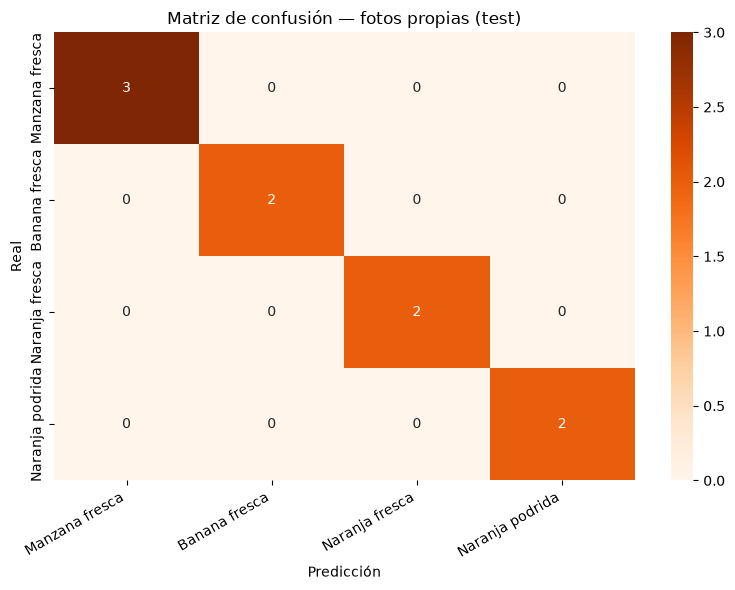


Prueba                                       ANTES   DESPUÉS
------------------------------------------------------------
Fotos propias con fruta (test)               66.7%    100.0%
Fotos propias, todas (incluye nada)              —    100.0%
Test de Kaggle                              99.85%    99.85%


In [9]:
resultados = {}
if propias_test:
    p_new, y_new = predecir_loader(modelo, propias_test_loader)
    resultados["propias_todas"] = float(accuracy_score(y_new, p_new))
    mask = np.array([clases[y] != "nada" for y in y_new])
    if mask.any():
        resultados["propias_con_fruta"] = float(np.mean(p_new[mask] == y_new[mask]))
    presentes = sorted(set(y_new) | set(p_new))
    print(classification_report(y_new, p_new, labels=presentes, target_names=[nombres[i] for i in presentes],
                                digits=3, zero_division=0))
    cm = confusion_matrix(y_new, p_new, labels=presentes)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Oranges",
                xticklabels=[nombres[i] for i in presentes], yticklabels=[nombres[i] for i in presentes])
    plt.xlabel("Predicción"); plt.ylabel("Real"); plt.title("Matriz de confusión — fotos propias (test)")
    plt.xticks(rotation=30, ha="right"); plt.tight_layout()
    plt.savefig(OUTPUTS_DIR / "matriz_confusion_propias.png", dpi=120)
    plt.show()

p_k, y_k = predecir_loader(modelo, kaggle_test_loader)
resultados["kaggle_test"] = float(accuracy_score(y_k, p_k))

print(f"\n{'Prueba':<40}{'ANTES':>10}{'DESPUÉS':>10}")
print("-" * 60)
if acc_antes is not None and "propias_con_fruta" in resultados:
    print(f"{'Fotos propias con fruta (test)':<40}{acc_antes*100:>9.1f}%{resultados['propias_con_fruta']*100:>9.1f}%")
if "propias_todas" in resultados:
    print(f"{'Fotos propias, todas (incluye nada)':<40}{'—':>10}{resultados['propias_todas']*100:>9.1f}%")
print(f"{'Test de Kaggle':<40}{'99.85%':>10}{resultados['kaggle_test']*100:>9.2f}%")

## 9. Ver predicciones en fotos propias de test

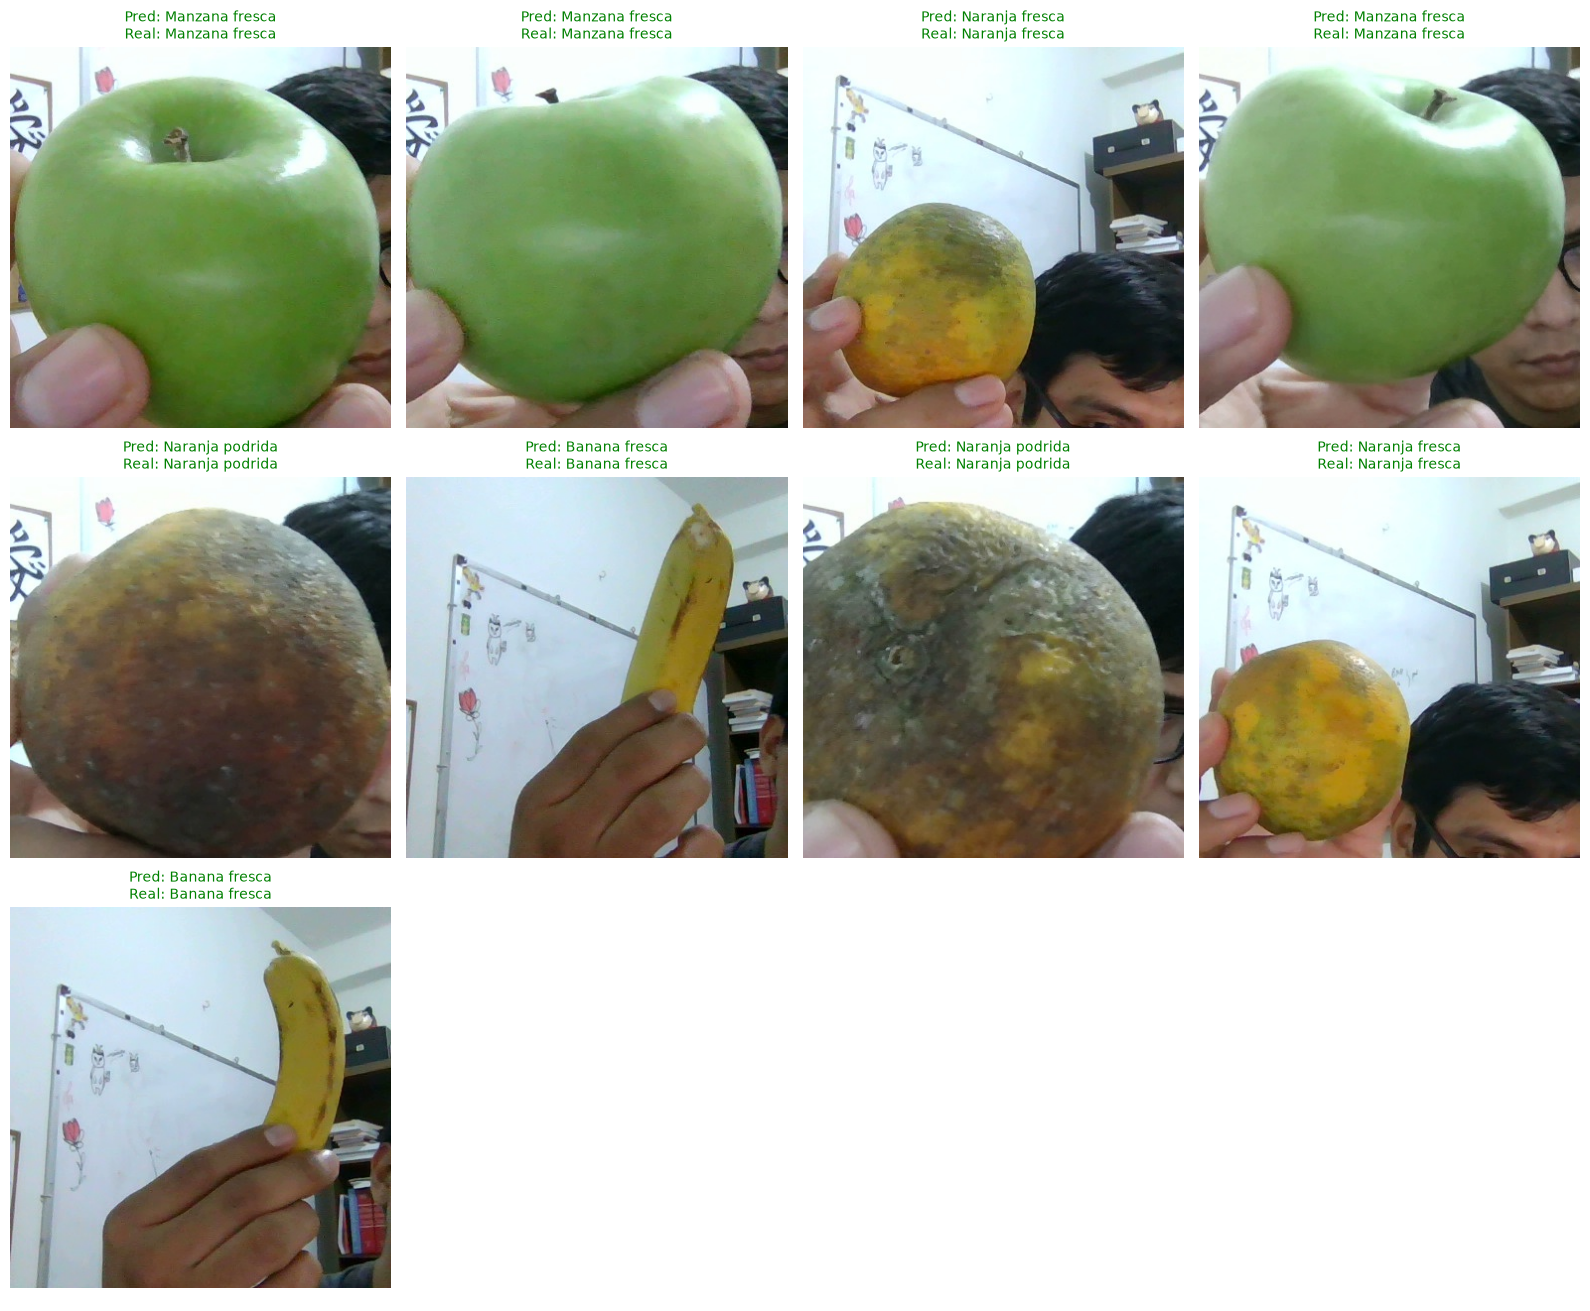

In [10]:
if propias_test:
    muestra = random.sample(range(len(propias_test)), min(12, len(propias_test)))
    filas = (len(muestra) + 3) // 4
    fig, axes = plt.subplots(filas, 4, figsize=(16, 4.4 * filas), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, i in zip(axes.flat, muestra):
        ruta, real = propias_test[i]
        ax.imshow(Image.open(ruta).convert("RGB"))
        ax.set_title(f"Pred: {nombres[p_new[i]]}\nReal: {nombres[real]}",
                     color="green" if p_new[i] == real else "red", fontsize=10)
    plt.tight_layout()
    plt.show()

## 10. Guardar, actualizar `config.json` y exportar a ONNX

El nuevo modelo pasa a ser el que usan la app y la página de cámara en vivo, porque ambas leen `models/config.json`. El modelo del notebook 02 (`frutas_resnet18.pth`) se conserva para poder comparar.

In [11]:
torch.save(modelo.cpu().state_dict(), MODELS_DIR / "frutas_resnet18_propias.pth")
config = {
    "modelo": "resnet18",
    "pesos": "frutas_resnet18_propias.pth",
    "onnx": "frutas_resnet18_propias.onnx",
    "img_size": IMG_SIZE, "mean": MEAN, "std": STD,
    "clases": clases,  # Incluye "nada" si capturaste fotos sin fruta
    "nombres_es": {c: NOMBRES_ES[c] for c in clases},
}
(MODELS_DIR / "config.json").write_text(json.dumps(config, indent=2, ensure_ascii=False), encoding="utf-8")
metricas = {"modelo": "ResNet18 + fotos propias", "clases": clases,
            "fotos_propias_train": len(propias_train), "fotos_propias_test": len(propias_test),
            "antes_propias_con_fruta": None if acc_antes is None else round(float(acc_antes), 4),
            **{k: round(v, 4) for k, v in resultados.items()},
            "tiempo_entrenamiento_s": round(tiempo_entrenamiento, 1)}
(OUTPUTS_DIR / "metricas_propias.json").write_text(json.dumps(metricas, indent=2, ensure_ascii=False), encoding="utf-8")
print(json.dumps(metricas, indent=2, ensure_ascii=False))

from src.exportar import exportar_onnx  # Exporta el modelo del config a ONNX y verifica
exportar_onnx()

{
  "modelo": "ResNet18 + fotos propias",
  "clases": [
    "freshapples",
    "freshbanana",
    "freshoranges",
    "nada",
    "rottenapples",
    "rottenbanana",
    "rottenoranges"
  ],
  "fotos_propias_train": 26,
  "fotos_propias_test": 9,
  "antes_propias_con_fruta": 0.6667,
  "propias_todas": 1.0,
  "propias_con_fruta": 1.0,
  "kaggle_test": 0.9985,
  "tiempo_entrenamiento_s": 91.7
}


W1027 20:10:59.349000 72884 Lib\site-packages\torch\utils\flop_counter.py:113] triton not found; flop counting will not work for triton kernels


[torch.onnx] Obtain model graph for `ResNet([...]` with `torch.export.export(..., strict=False)`...


[torch.onnx] Obtain model graph for `ResNet([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...


[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅


ONNX exportado: C:\dev\frutas-cnn\models\frutas_resnet18_propias.onnx (44.8 MB)


¿Coinciden PyTorch y ONNX? True (diferencia máxima: 2.35e-06)


True

## 11. Conclusiones

| Prueba | ANTES (solo Kaggle) | DESPUÉS (Kaggle + fotos propias) |
|---|---:|---:|
| Fotos propias con fruta (test, 9 fotos) | 66.7% (6 de 9) | **100%** (9 de 9) |
| Test de Kaggle (2,698) | 99.85% | 99.85% |

Datos: 35 fotos propias (11 de manzana fresca, 7 de banana fresca, 7 de naranja fresca, 7 de naranja podrida y 3 de "nada"). Se usaron 26 para entrenar y 9 para el test, separadas por tiempo. Entrenamiento: 1.5 min.

1. **El 99.85% de Kaggle no garantizaba nada en el mundo real:** con fotos de nuestra webcam, el mismo modelo bajaba a **66.7%**. Esto confirma el *domain shift* y el *data leakage* del test de Kaggle.
2. **Con apenas 26 fotos propias** (repetidas 8 veces por epoch) **y augmentation más fuerte**, el modelo acertó **todas** las fotos propias de test, y **no olvidó** lo que sabía: sigue con 99.85% en Kaggle.
3. **Hay que tomarlo con cautela:** son **solo 9 fotos de test**, sin fotos de "nada" en el test y sin manzanas ni bananas podridas propias. La mejora es clara, pero para afirmarlo con seguridad harían falta cientos de fotos propias variadas. Ese es el siguiente paso natural.
4. **Lección para la defensa:** en un proyecto real **los datos importan más que el modelo**. Pasar de la CNN propia a ResNet18 mejoró 0.8 puntos en Kaggle; agregar 26 fotos del dominio real mejoró **33 puntos** en el uso real.